### **Task 01**

In [11]:
def mp_neuron(inputs, weights, threshold):
    weighted_sum = sum(x * w for x, w in zip(inputs, weights))
    output = 1 if weighted_sum >= threshold else 0
    return output, weighted_sum
gates = {
    "2-Input AND Gate": {
        "inputs": [[0, 0], [0, 1], [1, 0], [1, 1]],
        "weights": [1, 1],
        "threshold": 2
    },
    "2-Input OR Gate": {
        "inputs": [[0, 0], [0, 1], [1, 0], [1, 1]],
        "weights": [1, 1],
        "threshold": 1
    },
    "1-Input NOT Gate": {
        "inputs": [[0], [1]],
        "weights": [-1],
        "threshold": 0
    },
    "3-Input AND Gate": {
        "inputs": [
            [0, 0, 0], [0, 0, 1], [0, 1, 0], [0, 1, 1],
            [1, 0, 0], [1, 0, 1], [1, 1, 0], [1, 1, 1]
        ],
        "weights": [1, 1, 1],
        "threshold": 3
    },
    "2-Input XOR Gate (Single M-P Attempt)": {
        "inputs": [[0, 0], [0, 1], [1, 0], [1, 1]],
        "weights": [1, 1],
        "threshold": 1
    }
}
for gate_name, config in gates.items():
    print("=" * 55)
    print(gate_name)
    print(f"Weights: {config['weights']}, Threshold: {config['threshold']}")
    header_inputs = " | ".join([f"X{i+1}" for i in range(len(config["inputs"][0]))])
    print(f"{header_inputs} | Weighted Sum | Output")
    print("-" * 55)
    for x in config["inputs"]:
        out, w_sum = mp_neuron(x, config["weights"], config["threshold"])
        str_inputs = " | ".join([str(val) for val in x])
        print(f"{str_inputs} | {w_sum:12} | {out:6}")
    print()

print("Derivation Analysis for XOR Gate:")
print("1. For (0, 0) -> 0: 0*w1 + 0*w2 < threshold  =>  threshold > 0")
print("2. For (0, 1) -> 1: 0*w1 + 1*w2 >= threshold =>  w2 >= threshold")
print("3. For (1, 0) -> 1: 1*w1 + 0*w2 >= threshold =>  w1 >= threshold")
print("   Summing equations 2 & 3: w1 + w2 >= 2 * threshold")
print("4. For (1, 1) -> 0: 1*w1 + 1*w2 < threshold  =>  w1 + w2 < threshold")
print("Combining: 2 * threshold <= w1 + w2 < threshold => 2 * threshold < threshold => threshold < 0")
print("Contradiction: threshold cannot be simultaneously > 0 and < 0.")
print("Conclusion: A single McCulloch-Pitts neuron cannot realize the XOR gate.")



2-Input AND Gate
Weights: [1, 1], Threshold: 2
X1 | X2 | Weighted Sum | Output
-------------------------------------------------------
0 | 0 |            0 |      0
0 | 1 |            1 |      0
1 | 0 |            1 |      0
1 | 1 |            2 |      1

2-Input OR Gate
Weights: [1, 1], Threshold: 1
X1 | X2 | Weighted Sum | Output
-------------------------------------------------------
0 | 0 |            0 |      0
0 | 1 |            1 |      1
1 | 0 |            1 |      1
1 | 1 |            2 |      1

1-Input NOT Gate
Weights: [-1], Threshold: 0
X1 | Weighted Sum | Output
-------------------------------------------------------
0 |            0 |      1
1 |           -1 |      0

3-Input AND Gate
Weights: [1, 1, 1], Threshold: 3
X1 | X2 | X3 | Weighted Sum | Output
-------------------------------------------------------
0 | 0 | 0 |            0 |      0
0 | 0 | 1 |            1 |      0
0 | 1 | 0 |            1 |      0
0 | 1 | 1 |            2 |      0
1 | 0 | 0 |            1 |   

### **Task 02**

AND Gate Final Weights: [0.2 0.1] Bias: -0.20000000000000004
AND Gate Predictions: [0 0 0 1]
OR Gate Final Weights: [0.1 0.1] Bias: -0.1
OR Gate Predictions: [0 1 1 1]
XOR Gate Misclassifications per Epoch: [3, 3, 4, 4, 4, 4, 4, 4, 4, 4]
XOR Gate Predictions: [1 1 0 0]


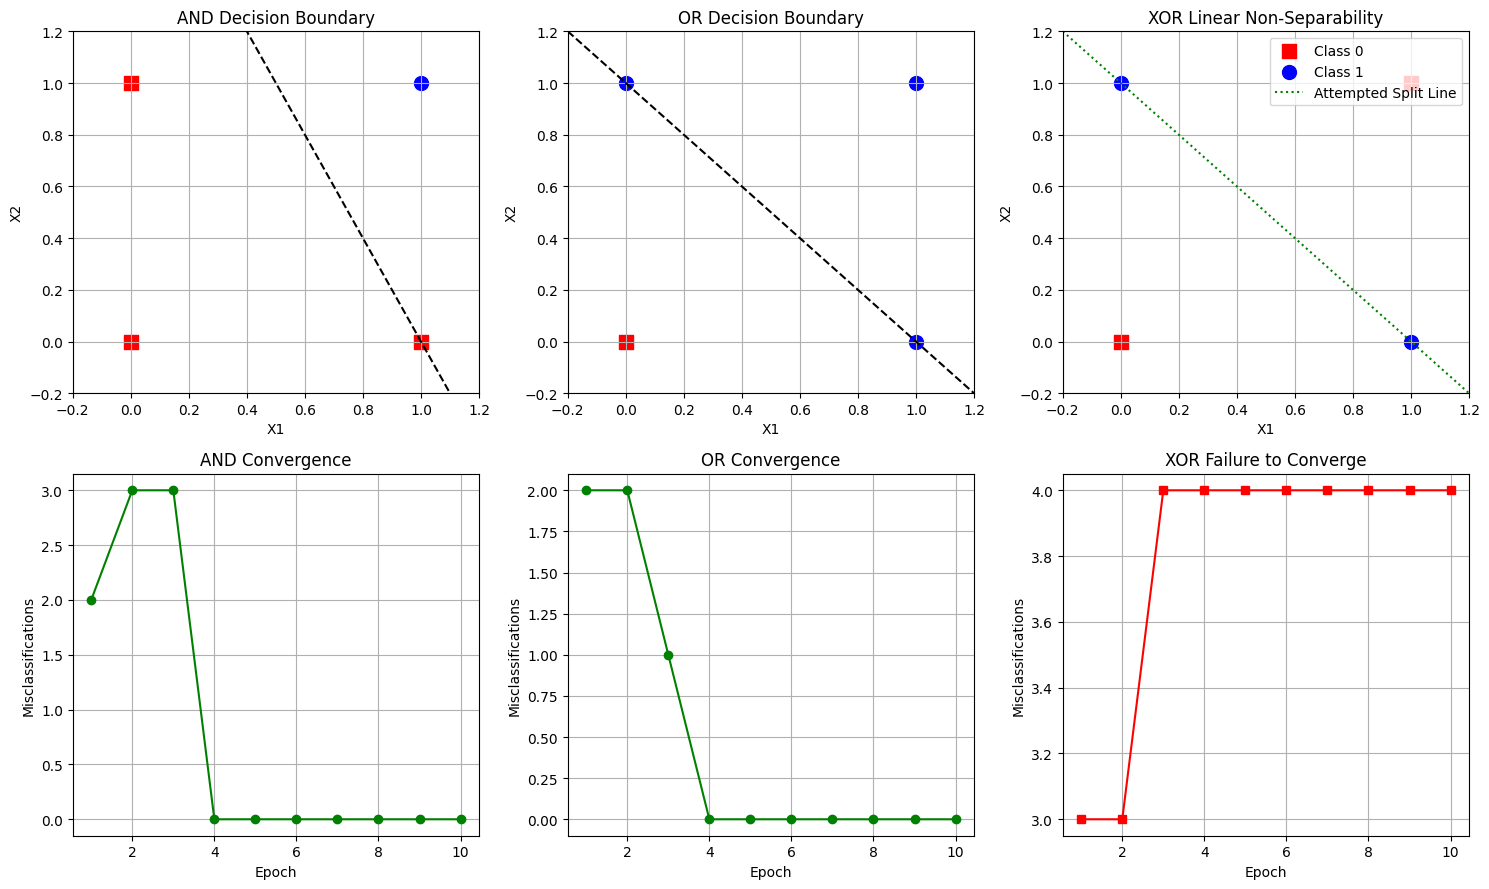

In [12]:
import numpy as np
import matplotlib.pyplot as plt

class Perceptron:
    def __init__(self):
        self.weights = None
        self.bias = None
        self.errors = []

    def fit(self, X, y, epochs=10, lr=0.1):
        self.weights = np.zeros(X.shape[1])
        self.bias = 0.0
        self.errors = []
        for _ in range(epochs):
            error_count = 0
            for xi, target in zip(X, y):
                net = np.dot(xi, self.weights) + self.bias
                pred = 1 if net >= 0 else 0
                update = lr * (target - pred)
                self.weights += update * xi
                self.bias += update
                if target != pred:
                    error_count += 1
            self.errors.append(error_count)

    def predict(self, X):
        return np.where((np.dot(X, self.weights) + self.bias) >= 0, 1, 0)

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_and = np.array([0, 0, 0, 1])
y_or = np.array([0, 1, 1, 1])
y_xor = np.array([0, 1, 1, 0])

p_and = Perceptron()
p_and.fit(X, y_and, epochs=10, lr=0.1)

p_or = Perceptron()
p_or.fit(X, y_or, epochs=10, lr=0.1)

p_xor = Perceptron()
p_xor.fit(X, y_xor, epochs=10, lr=0.1)

print("AND Gate Final Weights:", p_and.weights, "Bias:", p_and.bias)
print("AND Gate Predictions:", p_and.predict(X))
print("OR Gate Final Weights:", p_or.weights, "Bias:", p_or.bias)
print("OR Gate Predictions:", p_or.predict(X))
print("XOR Gate Misclassifications per Epoch:", p_xor.errors)
print("XOR Gate Predictions:", p_xor.predict(X))

fig, axs = plt.subplots(2, 3, figsize=(15, 9))

def plot_boundary(ax, p, X, y, title):
    for i in range(len(X)):
        if y[i] == 1:
            ax.scatter(X[i, 0], X[i, 1], color="blue", marker="o", s=100)
        else:
            ax.scatter(X[i, 0], X[i, 1], color="red", marker="s", s=100)
    x1_vals = np.linspace(-0.2, 1.2, 100)
    if p.weights[1] != 0:
        x2_vals = -(p.weights[0] * x1_vals + p.bias) / p.weights[1]
        ax.plot(x1_vals, x2_vals, "k--")
    ax.set_xlim(-0.2, 1.2)
    ax.set_ylim(-0.2, 1.2)
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.set_title(title)
    ax.grid(True)

plot_boundary(axs[0, 0], p_and, X, y_and, "AND Decision Boundary")
plot_boundary(axs[0, 1], p_or, X, y_or, "OR Decision Boundary")

axs[0, 2].scatter([0, 1], [0, 1], color="red", marker="s", s=100, label="Class 0")
axs[0, 2].scatter([0, 1], [1, 0], color="blue", marker="o", s=100, label="Class 1")
axs[0, 2].plot([-0.2, 1.2], [1.2, -0.2], "g:", label="Attempted Split Line")
axs[0, 2].set_xlim(-0.2, 1.2)
axs[0, 2].set_ylim(-0.2, 1.2)
axs[0, 2].set_xlabel("X1")
axs[0, 2].set_ylabel("X2")
axs[0, 2].set_title("XOR Linear Non-Separability")
axs[0, 2].legend(loc="upper right")
axs[0, 2].grid(True)

axs[1, 0].plot(range(1, 11), p_and.errors, marker="o", color="green")
axs[1, 0].set_xlabel("Epoch")
axs[1, 0].set_ylabel("Misclassifications")
axs[1, 0].set_title("AND Convergence")
axs[1, 0].grid(True)

axs[1, 1].plot(range(1, 11), p_or.errors, marker="o", color="green")
axs[1, 1].set_xlabel("Epoch")
axs[1, 1].set_ylabel("Misclassifications")
axs[1, 1].set_title("OR Convergence")
axs[1, 1].grid(True)

axs[1, 2].plot(range(1, 11), p_xor.errors, marker="s", color="red")
axs[1, 2].set_xlabel("Epoch")
axs[1, 2].set_ylabel("Misclassifications")
axs[1, 2].set_title("XOR Failure to Converge")
axs[1, 2].grid(True)

plt.tight_layout()
plt.show()


### **Task 03**

MLP Training on XOR:
Converged at Epoch: 482
Final MSE Loss: 0.009955801130965324
Final Predictions:
Input: [0. 0.] -> Target: 0 -> Pred: 0.0556 -> Class: 0
Input: [0. 1.] -> Target: 1 -> Pred: 0.8994 -> Class: 1
Input: [1. 0.] -> Target: 1 -> Pred: 0.9086 -> Class: 1
Input: [1. 1.] -> Target: 0 -> Pred: 0.1351 -> Class: 0


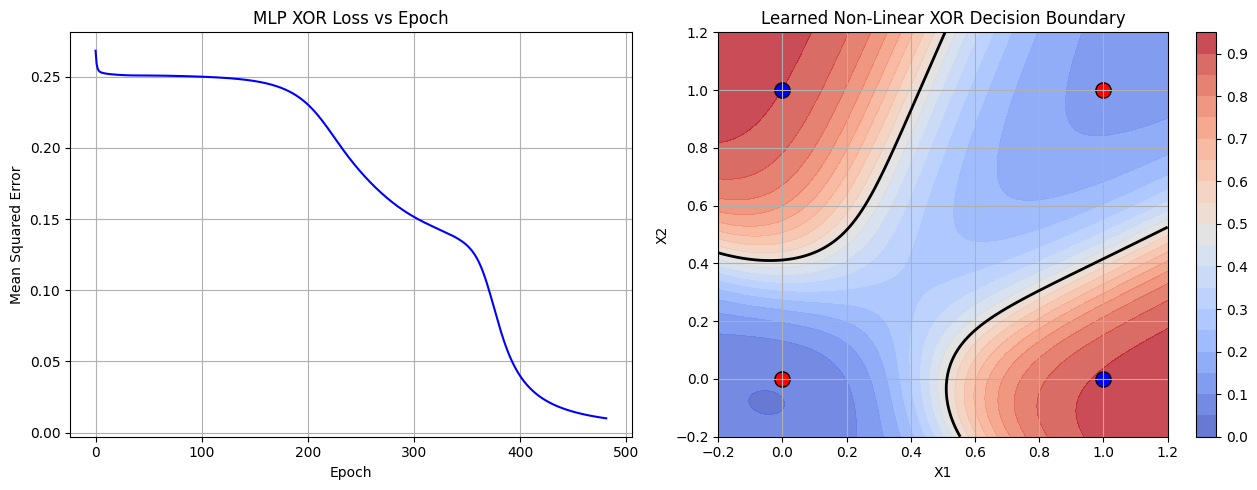


--- Experiment: Varying Hidden Neurons & Learning Rates ---
Hidden Neurons  | Learning Rate   | Epochs to Converge   | Final MSE    | Status
---------------------------------------------------------------------------
2               | 0.01            | 10000                | 0.245939     | Max Epochs
2               | 0.1             | 10000                | 0.126355     | Max Epochs
2               | 1.0             | 515                  | 0.009915     | Converged
4               | 0.01            | 10000                | 0.209282     | Max Epochs
4               | 0.1             | 3135                 | 0.009999     | Converged
4               | 1.0             | 482                  | 0.009956     | Converged
8               | 0.01            | 10000                | 0.038098     | Max Epochs
8               | 0.1             | 1665                 | 0.009992     | Converged
8               | 1.0             | 158                  | 0.009954     | Converged


In [13]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def sigmoid_deriv(a):
    return a * (1.0 - a)

class MLP:
    def __init__(self, input_dim=2, hidden_dim=4, output_dim=1, seed=42):
        np.random.seed(seed)
        self.W1 = np.random.randn(input_dim, hidden_dim) * np.sqrt(2.0 / input_dim)
        self.b1 = np.zeros((1, hidden_dim))
        self.W2 = np.random.randn(hidden_dim, output_dim) * np.sqrt(2.0 / hidden_dim)
        self.b2 = np.zeros((1, output_dim))

    def forward(self, X):
        self.z1 = np.dot(X, self.W1) + self.b1
        self.a1 = sigmoid(self.z1)
        self.z2 = np.dot(self.a1, self.W2) + self.b2
        self.a2 = sigmoid(self.z2)
        return self.a2

    def train_epoch(self, X, y, lr=1.0):
        for i in range(len(X)):
            xi = X[i:i+1]
            yi = y[i:i+1]
            z1 = np.dot(xi, self.W1) + self.b1
            a1 = sigmoid(z1)
            z2 = np.dot(a1, self.W2) + self.b2
            a2 = sigmoid(z2)

            delta2 = -2.0 * (yi - a2) * sigmoid_deriv(a2)
            dW2 = np.dot(a1.T, delta2)
            db2 = delta2
            delta1 = np.dot(delta2, self.W2.T) * sigmoid_deriv(a1)
            dW1 = np.dot(xi.T, delta1)
            db1 = delta1

            self.W2 -= lr * dW2
            self.b2 -= lr * db2
            self.W1 -= lr * dW1
            self.b1 -= lr * db1

    def fit(self, X, y, epochs=10000, lr=1.0, tol=0.01):
        losses = []
        for epoch in range(epochs):
            pred = self.forward(X)
            loss = np.mean((y - pred) ** 2)
            losses.append(loss)
            if loss < tol:
                return epoch + 1, losses
            self.train_epoch(X, y, lr=lr)
        return epochs, losses

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)

mlp = MLP(hidden_dim=4, seed=42)
conv_epoch, loss_history = mlp.fit(X, y, epochs=5000, lr=1.0, tol=0.01)

print("MLP Training on XOR:")
print("Converged at Epoch:", conv_epoch)
print("Final MSE Loss:", loss_history[-1])
print("Final Predictions:")
final_preds = mlp.forward(X)
for i in range(len(X)):
    print(f"Input: {X[i]} -> Target: {int(y[i][0])} -> Pred: {final_preds[i][0]:.4f} -> Class: {int(final_preds[i][0] > 0.5)}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
ax1.plot(loss_history, color="blue")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Mean Squared Error")
ax1.set_title("MLP XOR Loss vs Epoch")
ax1.grid(True)

xx, yy = np.meshgrid(np.linspace(-0.2, 1.2, 200), np.linspace(-0.2, 1.2, 200))
grid_points = np.c_[xx.ravel(), yy.ravel()]
zz = mlp.forward(grid_points).reshape(xx.shape)

contour = ax2.contourf(xx, yy, zz, levels=20, cmap="coolwarm", alpha=0.8)
plt.colorbar(contour, ax=ax2)
ax2.contour(xx, yy, zz, levels=[0.5], colors="black", linewidths=2)

for i in range(len(X)):
    if y[i] == 1:
        ax2.scatter(X[i, 0], X[i, 1], color="blue", edgecolors="black", s=120)
    else:
        ax2.scatter(X[i, 0], X[i, 1], color="red", edgecolors="black", s=120)
ax2.set_xlabel("X1")
ax2.set_ylabel("X2")
ax2.set_title("Learned Non-Linear XOR Decision Boundary")
ax2.grid(True)

plt.tight_layout()
plt.show()

print("\n--- Experiment: Varying Hidden Neurons & Learning Rates ---")
print(f"{'Hidden Neurons':<15} | {'Learning Rate':<15} | {'Epochs to Converge':<20} | {'Final MSE':<12} | {'Status'}")
print("-" * 75)
for h in [2, 4, 8]:
    for lr_val in [0.01, 0.1, 1.0]:
        test_mlp = MLP(hidden_dim=h, seed=42)
        ep, hist = test_mlp.fit(X, y, epochs=10000, lr=lr_val, tol=0.01)
        status = "Converged" if hist[-1] < 0.01 else "Max Epochs"
        print(f"{h:<15} | {lr_val:<15} | {ep:<20} | {hist[-1]:<12.6f} | {status}")


### **Task 04**

Demonstrating Symmetry Breaking Failure for Zero Initialization:

Epoch 1 Hidden Weight Matrix (W1):
[[-0.00893636 -0.00893636]
 [-0.01897712 -0.01897712]]
Neuron 1 weights: [-0.00893636 -0.01897712]
Neuron 2 weights: [-0.00893636 -0.01897712]
Identical across neurons: True

Epoch 5 Hidden Weight Matrix (W1):
[[-0.04314051 -0.04314051]
 [-0.09189227 -0.09189227]]
Neuron 1 weights: [-0.04314051 -0.09189227]
Neuron 2 weights: [-0.04314051 -0.09189227]
Identical across neurons: True

Epoch 10 Hidden Weight Matrix (W1):
[[-0.08231725 -0.08231725]
 [-0.17495894 -0.17495894]]
Neuron 1 weights: [-0.08231725 -0.17495894]
Neuron 2 weights: [-0.08231725 -0.17495894]
Identical across neurons: True


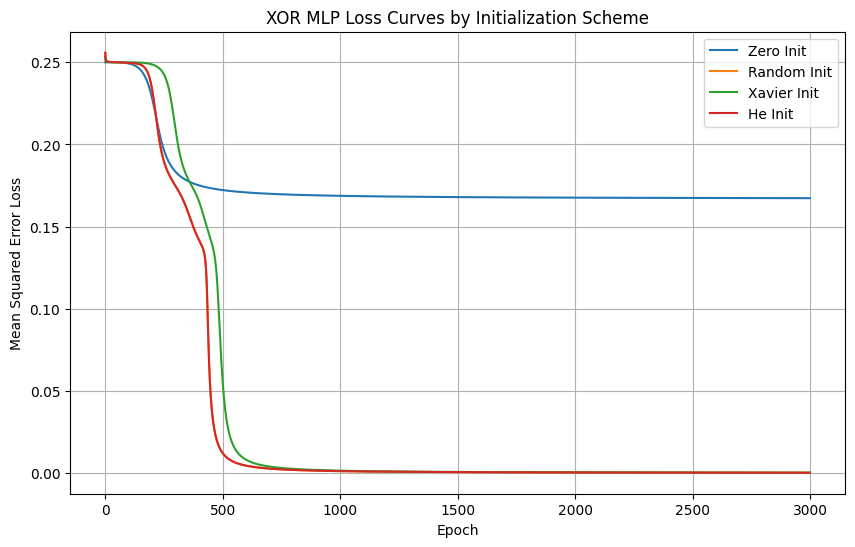


--- Initialization Scheme Performance Comparison ---
Scheme       | Epochs to Converge     | Final Loss   | Convergence Status
---------------------------------------------------------------------------
Zero         | Did not converge (3000) | 0.167327     | Failed (Symmetry Breaking)
Random       | 515                    | 0.000251     | Converged
Xavier       | 582                    | 0.000269     | Converged
He           | 515                    | 0.000251     | Converged


In [14]:
import numpy as np
import matplotlib.pyplot as plt
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def sigmoid_deriv(a):
    return a * (1.0 - a)

class MLPInit:
    def __init__(self, input_dim=2, hidden_dim=2, output_dim=1, init_method="random", seed=42):
        np.random.seed(seed)
        if init_method == "zero":
            self.W1 = np.zeros((input_dim, hidden_dim))
            self.W2 = np.zeros((hidden_dim, output_dim))
        elif init_method == "random":
            self.W1 = np.random.randn(input_dim, hidden_dim)
            self.W2 = np.random.randn(hidden_dim, output_dim)
        elif init_method == "xavier":
            l1 = np.sqrt(2.0 / (input_dim + hidden_dim))
            l2 = np.sqrt(2.0 / (hidden_dim + output_dim))
            self.W1 = np.random.randn(input_dim, hidden_dim) * l1
            self.W2 = np.random.randn(hidden_dim, output_dim) * l2
        elif init_method == "he":
            self.W1 = np.random.randn(input_dim, hidden_dim) * np.sqrt(2.0 / input_dim)
            self.W2 = np.random.randn(hidden_dim, output_dim) * np.sqrt(2.0 / hidden_dim)
        self.b1 = np.zeros((1, hidden_dim))
        self.b2 = np.zeros((1, output_dim))
        self.init_method = init_method
    def forward(self, X):
        self.z1 = np.dot(X, self.W1) + self.b1
        self.a1 = sigmoid(self.z1)
        self.z2 = np.dot(self.a1, self.W2) + self.b2
        self.a2 = sigmoid(self.z2)
        return self.a2
    def train_epoch(self, X, y, lr=1.0):
        for i in range(len(X)):
            xi = X[i:i+1]
            yi = y[i:i+1]
            z1 = np.dot(xi, self.W1) + self.b1
            a1 = sigmoid(z1)
            z2 = np.dot(a1, self.W2) + self.b2
            a2 = sigmoid(z2)

            delta2 = -2.0 * (yi - a2) * sigmoid_deriv(a2)
            dW2 = np.dot(a1.T, delta2)
            db2 = delta2
            delta1 = np.dot(delta2, self.W2.T) * sigmoid_deriv(a1)
            dW1 = np.dot(xi.T, delta1)
            db1 = delta1

            self.W2 -= lr * dW2
            self.b2 -= lr * db2
            self.W1 -= lr * dW1
            self.b1 -= lr * db1
    def fit(self, X, y, epochs=3000, lr=1.0, tol=0.01):
        losses = []
        converged_epoch = None
        for epoch in range(1, epochs + 1):
            pred = self.forward(X)
            loss = np.mean((y - pred) ** 2)
            losses.append(loss)
            if loss < tol and converged_epoch is None:
                converged_epoch = epoch
            self.train_epoch(X, y, lr=lr)
        return converged_epoch, losses
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)

print("Demonstrating Symmetry Breaking Failure for Zero Initialization:")
mlp_zero_demo = MLPInit(hidden_dim=2, init_method="zero", seed=42)
for ep in range(1, 11):
    mlp_zero_demo.train_epoch(X, y, lr=1.0)
    if ep in [1, 5, 10]:
        print(f"\nEpoch {ep} Hidden Weight Matrix (W1):")
        print(mlp_zero_demo.W1)
        print(f"Neuron 1 weights: {mlp_zero_demo.W1[:, 0]}")
        print(f"Neuron 2 weights: {mlp_zero_demo.W1[:, 1]}")
        print("Identical across neurons:", np.array_equal(mlp_zero_demo.W1[:, 0], mlp_zero_demo.W1[:, 1]))
methods = ["zero", "random", "xavier", "he"]
results = {}
plt.figure(figsize=(10, 6))

for m in methods:
    model = MLPInit(hidden_dim=2, init_method=m, seed=42)
    ep_conv, loss_curve = model.fit(X, y, epochs=3000, lr=1.0, tol=0.01)
    results[m] = {"converged_epoch": ep_conv, "final_loss": loss_curve[-1], "losses": loss_curve}
    plt.plot(loss_curve, label=f"{m.capitalize()} Init")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error Loss")
plt.title("XOR MLP Loss Curves by Initialization Scheme")
plt.legend()
plt.grid(True)
plt.show()
print("\n--- Initialization Scheme Performance Comparison ---")
print(f"{'Scheme':<12} | {'Epochs to Converge':<22} | {'Final Loss':<12} | {'Convergence Status'}")
print("-" * 75)
for m in methods:
    conv_str = str(results[m]["converged_epoch"]) if results[m]["converged_epoch"] else "Did not converge (3000)"
    status_str = "Converged" if results[m]["converged_epoch"] else "Failed (Symmetry Breaking)"
    print(f"{m.capitalize():<12} | {conv_str:<22} | {results[m]['final_loss']:<12.6f} | {status_str}")
